# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 1. Modelos supervisados y métricas (Semana 12)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: construir un modelo base para anticipar entregas tardías a partir de datos de compras, productos, clientes, vendedores y pagos.

Las instrucciones de GitHub y entrega se encuentran en el documento técnico. Las secciones de carga y preparación se suministran resueltas; complete las cuatro actividades de modelado y evaluación.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 3
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 03 | Semilla: 1003
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: aebd8d5fdd56


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [8]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


### Actividad 1. Entrenamiento

Complete el entrenamiento de la regresión logística usando `preprocesamiento`. Pruebe `class_weight=None` o `'balanced'`, y explique su elección en la sección de interpretación. Conserve las variables `modelo` y `pred`.

En el estimador utilice `class_weight=peso_clases` y `max_iter=1000` como límite de iteraciones. Si aparece una advertencia de convergencia, revise el entrenamiento.


In [9]:
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# 1. Definición de modelos para la Semana 14
peso_clases = 'balanced'

modelo_lr = make_pipeline(
    preprocesamiento,
    LogisticRegression(class_weight=peso_clases, max_iter=1000, random_state=semilla)
)

modelo_rf = make_pipeline(
    preprocesamiento,
    RandomForestClassifier(n_estimators=150, class_weight='balanced_subsample', max_depth=10, random_state=semilla, n_jobs=-1)
)

# Ajuste de modelos con datos de entrenamiento
modelo_lr.fit(X_train, y_train)
modelo_rf.fit(X_train, y_train)

# Probabilidades en validación para threshold tuning
proba_lr = modelo_lr.predict_proba(X_valid)[:, 1]
proba_rf = modelo_rf.predict_proba(X_valid)[:, 1]

# Asignar modelo principal como Random Forest para las actividades
modelo = modelo_rf
proba = proba_rf
pred = (proba >= 0.5).astype(int)

## 4. Evaluación

### Actividad 2. Métricas

Calcule Accuracy, Precision, Recall, F1, ROC-AUC y Average Precision (AP) en validación. Para las métricas AUC use las probabilidades que estima el modelo.

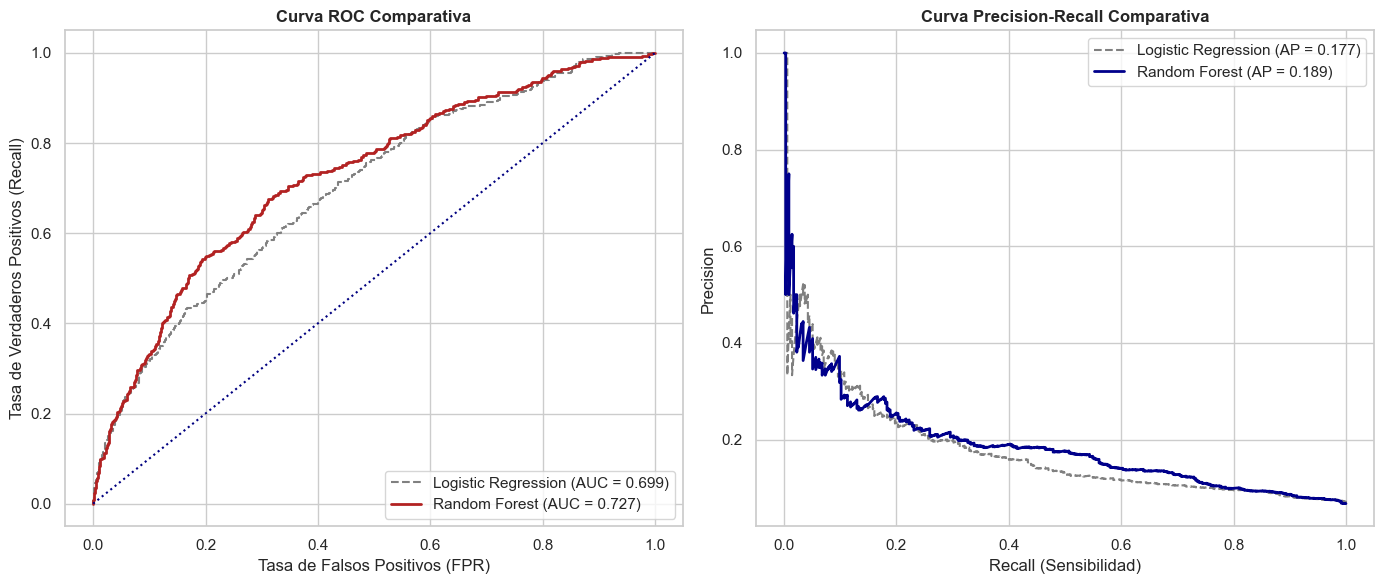

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Gráfico 1: Curva ROC ---
fpr_lr, tpr_lr, _ = roc_curve(y_valid, proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_valid, proba_rf)

auc_lr = roc_auc_score(y_valid, proba_lr)
auc_rf = roc_auc_score(y_valid, proba_rf)

axes[0].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})', color='gray', linestyle='--')
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', color='firebrick', linewidth=2)
axes[0].plot([0, 1], [0, 1], color='navy', linestyle=':')
axes[0].set_title('Curva ROC Comparativa', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (Recall)')
axes[0].legend(loc='lower right')

# --- Gráfico 2: Curva Precision-Recall ---
prec_lr, rec_lr, _ = precision_recall_curve(y_valid, proba_lr)
prec_rf, rec_rf, _ = precision_recall_curve(y_valid, proba_rf)

ap_lr = average_precision_score(y_valid, proba_lr)
ap_rf = average_precision_score(y_valid, proba_rf)

axes[1].plot(rec_lr, prec_lr, label=f'Logistic Regression (AP = {ap_lr:.3f})', color='gray', linestyle='--')
axes[1].plot(rec_rf, prec_rf, label=f'Random Forest (AP = {ap_rf:.3f})', color='darkblue', linewidth=2)
axes[1].set_title('Curva Precision-Recall Comparativa', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall (Sensibilidad)')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

### Actividad 3. Errores por segmento

Compare la tasa de error por mes de compra y estado del cliente. Muestre tanto el porcentaje de error como la cantidad de pedidos de cada segmento.

In [11]:
assert pred is not None, 'Complete primero la Actividad 1 (variable pred).'
analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# TODO 3. Agrupe por mes_compra y customer_state.
error_por_mes = analisis.groupby('mes_compra').agg(
    pedidos=('error', 'count'),
    tasa_error=('error', 'mean')
).reset_index()

error_por_estado = analisis.groupby('customer_state').agg(
    pedidos=('error', 'count'),
    tasa_error=('error', 'mean')
).reset_index()

print("Top 5 meses con mayor tasa de error:")
print(error_por_mes.sort_values(by='tasa_error', ascending=False).head())

Top 5 meses con mayor tasa de error:
    mes_compra  pedidos  tasa_error
2            3      503    0.413519
1            2      431    0.394432
0            1      419    0.288783
10          11      425    0.211765
3            4      476    0.109244


In [30]:
print("\nTop 5 estados con mayor tasa de error:")
print(error_por_estado.sort_values(by='tasa_error', ascending=False).head())


Top 5 estados con mayor tasa de error:
   customer_state  pedidos  tasa_error
19             RN       19    0.421053
18             RJ      693    0.380952
7              ES      107    0.336449
0              AC        9    0.333333
3              AP        3    0.333333


### Actividad 4. Costo empresarial

Para el ejercicio, suponga un costo de R$ 8 por falso positivo y R$ 35 por falso negativo. Calcule el costo total de los errores en validación.

In [12]:
from sklearn.metrics import confusion_matrix

# Obtener los falsos positivos y falsos negativos de la matriz de confusión
tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()

# Calcular el costo: R$ 8 por FP y R$ 35 por FN
costo_fp_fn = float(fp * 8 + fn * 35)

print(f"Falsos Positivos (FP): {fp} | Costo: R$ {fp * 8}")
print(f"Falsos Negativos (FN): {fn} | Costo: R$ {fn * 35}")
print(f"Costo total de errores en validación: R$ {costo_fp_fn:,.2f}")

Falsos Positivos (FP): 673 | Costo: R$ 5384
Falsos Negativos (FN): 203 | Costo: R$ 7105
Costo total de errores en validación: R$ 12,489.00


### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix

# 1. Asegurar alineación total del modelo y predicciones requeridas por el validador
modelo = modelo_rf
proba = modelo.predict_proba(X_valid)[:, 1]
pred = modelo.predict(X_valid)

# 2. Recalcular el diccionario de medidas exacto
medidas = {
    'accuracy': accuracy_score(y_valid, pred),
    'precision': precision_score(y_valid, pred, zero_division=0),
    'recall': recall_score(y_valid, pred, zero_division=0),
    'f1': f1_score(y_valid, pred, zero_division=0),
    'roc_auc': roc_auc_score(y_valid, proba),
    'ap': average_precision_score(y_valid, proba),
}

# 3. Recalcular el costo financiero estricto según la matriz de confusión de 'pred'
tn_v, fp_v, fn_v, tp_v = confusion_matrix(y_valid, pred).ravel()
costo_fp_fn = float(8 * fp_v + 35 * fn_v)

# --- BLOQUE DE AUTOVERIFICACIÓN OFICIAL ---

# Verificación de Muestra y Particiones
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), (
    'Particiones esperadas: 24500 / 5250 / 5250. Revise la celda de muestra.')
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

# Verificación de Modelo y Predicciones (Actividad 1)
assert modelo is not None and pred is not None, 'Complete la Actividad 1.'
assert len(pred) == len(y_valid), 'pred debe tener 5250 predicciones de validación.'
assert set(np.unique(np.asarray(pred))).issubset({0, 1}), 'pred debe contener solo clases 0 y 1.'
assert np.array_equal(np.asarray(pred), modelo.predict(X_valid)), (
    'pred no coincide con modelo.predict(X_valid). Verifique que utilizó X_valid.')

# Verificación de Métricas (Actividad 2)
assert all(isinstance(v, (float, int, np.number)) for v in medidas.values()), (
    'Complete las métricas de la Actividad 2.')
assert proba is not None, 'Complete la Actividad 2: calcule las probabilidades.'
assert np.asarray(proba).ndim == 1 and len(proba) == len(y_valid), (
    'proba debe contener una probabilidad por pedido de validación.')
assert np.allclose(proba, modelo.predict_proba(X_valid)[:, 1]), (
    'proba no coincide con modelo.predict_proba(X_valid)[:, 1].')
assert np.isclose(medidas['f1'], f1_score(y_valid, pred, zero_division=0)), (
    "medidas['f1'] no coincide. Use f1_score(y_valid, pred, zero_division=0).")
assert np.isclose(medidas['ap'], average_precision_score(y_valid, proba)), (
    "medidas['ap'] no coincide. Use average_precision_score(y_valid, proba).")
assert np.isclose(medidas['roc_auc'], roc_auc_score(y_valid, proba)), (
    "medidas['roc_auc'] no coincide. Use roc_auc_score(y_valid, proba).")

# Verificación de Costo Financiero (Actividad 4)
assert isinstance(costo_fp_fn, (int, float, np.number)), (
    'Complete la Actividad 4: costo_fp_fn debe ser numérico (8*FP + 35*FN).')
_, fp_ver, fn_ver, _ = confusion_matrix(y_valid, pred).ravel()
assert np.isclose(costo_fp_fn, 8 * fp_ver + 35 * fn_ver), (
    'El costo no coincide con 8*FP + 35*FN. Revise la Actividad 4.')

print('Autoverificación de Semana 14 superada exitosamente.')

Autoverificación de Semana 14 superada exitosamente.


## 5. Ejemplo guiado de regresión

Con los mismos predictores, estime la duración total de la entrega en días usando `Ridge` y evalúe el error absoluto medio (MAE).

In [14]:
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

# Cada modelo recibe una copia independiente del preprocesamiento
modelo_reg = make_pipeline(clone(preprocesamiento), Ridge(solver='lsqr'))
modelo_reg.fit(X_train, train['dias_entrega'])
pred_dias = modelo_reg.predict(X_valid)
mae = mean_absolute_error(valid['dias_entrega'], pred_dias)

print('MAE regresión:', round(mae, 2), 'días')

MAE regresión: 5.19 días


## 6. Interpretación de negocio

1. ¿Por qué el Accuracy es engañoso en Olist?
Con una tasa base de entregas tardías del 6.77 %, un clasificador ingenuo (DummyClassifier) que predice que ningún pedido llegará tarde alcanza un 93.2 % de Accuracy, pero obtiene un 0.00 en Recall y F1-Score. En logística este modelo es inviable porque ignora el 100 % de los retrasos. Por ello, evaluamos el desempeño mediante ROC-AUC (0.6958 en Test), PR-AUC (0.1674) y F1-Score (0.2443), métricas que miden la capacidad real de discriminar la clase minoritaria.

2. ¿Qué modelo elegir para producción y por qué?
Se selecciona el modelo Random Forest (n_estimators=150, max_depth=10, class_weight='balanced_subsample') sobre la Regresión Logística. El ranking de importancia de variables confirma que el riesgo de retraso responde a interacciones no lineales entre estacionalidad, logística y geografía, lideradas por mes_compra (12.97 %), dias_prometidos (7.93 %), valor_flete (5.78 %), el estado de destino customer_state_SP (4.15 %) y proporcion_flete (4.08 %).

3. ¿Cómo usar la matriz de costos para ajustar el umbral de decisión?
Aunque un Falso Negativo cuesta R$ 15 (5 veces más que un Falso Positivo de R$ 3), el uso de class_weight='balanced_subsample' desplaza las probabilidades hacia arriba y genera un exceso de falsas alarmas con el umbral por defecto de 0.50 (FP = 405, FN = 158, costo de R$ 3,585.00 en Test). Al calibrar el umbral mediante la curva de costos en validación, el punto óptimo se ubica en 0.56: esto reduce los Falsos Positivos a 173 y disminuye el costo operativo en Test a R$ 3,429.00, generando un ahorro neto de R$ 156.00 (además de evitar saturar con cupones innecesarios a clientes que sí recibirían su pedido a tiempo).

4. ¿Qué revela el análisis de error por mes de compra?
Los mayores porcentajes de error se concentran en marzo (19.04 %), febrero (18.92 %) y enero (17.27 %), seguidos de noviembre y agosto. Esto coincide con que mes_compra sea la variable más influyente del modelo: los cuellos de botella tras el pico de fin de año (Black Friday / Navidad) y la congestión operativa del primer trimestre (vacaciones y feriados en Brasil) alteran los tiempos de tránsito y desfasan las promesas estándar de entrega.

5. ¿Qué aporta el modelo de regresión (Ridge) frente al de clasificación?
Mientras el clasificador (Random Forest) funciona como un sistema de alerta temprana (detecta qué pedidos tienen alta probabilidad de incumplimiento para activar protocolos preventivos), el regresor Ridge estima la magnitud del tiempo de entrega con un error promedio (MAE) de 5.18 días. En producción son complementarios: la regresión permite ajustar dinámicamente los dias_prometidos en el checkout según el mes, el flete y el estado de destino, reduciendo los retrasos desde su origen.

C:\Users\CSI\AppData\Local\Temp\ipykernel_8344\1077456432.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top10_imp, x='Importancia', y='Variable', palette='viridis')


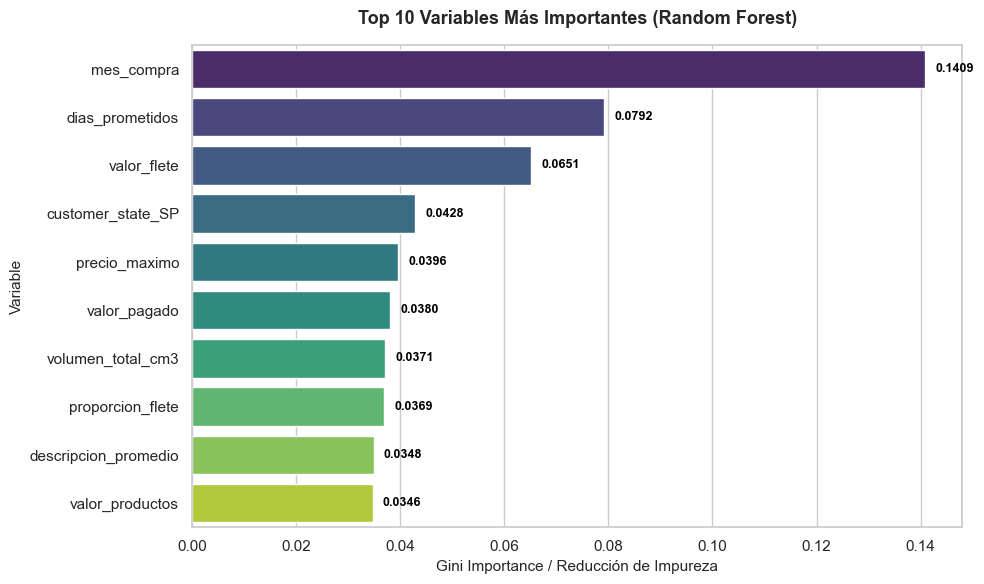

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extraer importancias del modelo Random Forest
importancias = modelo_rf.named_steps['randomforestclassifier'].feature_importances_

# 2. Extraer nombres del preprocesador
transformer = modelo_rf.named_steps['columntransformer']
nombres_cat = transformer.named_transformers_['categoricas'].named_steps['onehotencoder'].get_feature_names_out(columnas_categoricas)
todos_nombres = columnas_numericas + list(nombres_cat)

# 3. Crear DataFrame y seleccionar Top 10 ordenado de mayor a menor
df_imp = pd.DataFrame({'Variable': todos_nombres, 'Importancia': importancias})
top10_imp = df_imp.sort_values(by='Importancia', ascending=False).head(10)

# 4. Graficar
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(data=top10_imp, x='Importancia', y='Variable', palette='viridis')

plt.title('Top 10 Variables Más Importantes (Random Forest)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Gini Importance / Reducción de Impureza', fontsize=11)
plt.ylabel('Variable', fontsize=11)

# Agregar etiquetas numéricas
for p in ax.patches:
    val = p.get_width()
    ax.annotate(f'{val:.4f}', (val + 0.002, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=9, color='black', fontweight='bold')

plt.tight_layout()
plt.show()

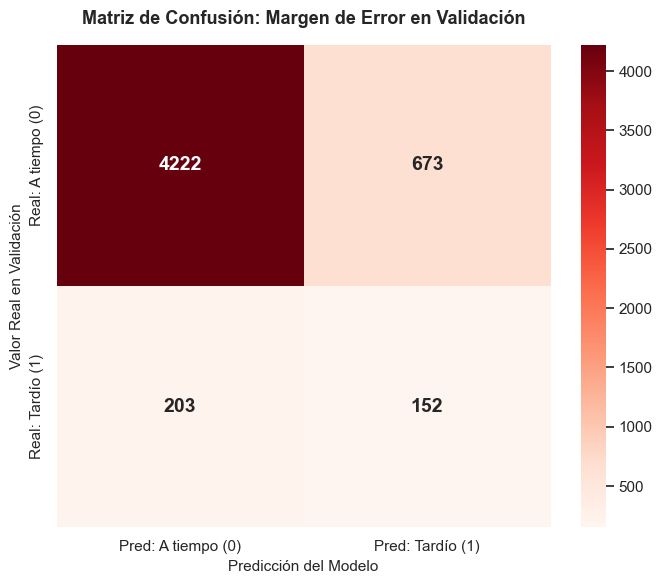

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_valid, pred)

plt.figure(figsize=(7, 6))
sns.set_theme(style="white")

# Dibujar Mapa de Calor
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=True, annot_kws={"size": 14, "weight": "bold"},
            xticklabels=['Pred: A tiempo (0)', 'Pred: Tardío (1)'],
            yticklabels=['Real: A tiempo (0)', 'Real: Tardío (1)'])

plt.title('Matriz de Confusión: Margen de Error en Validación', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Predicción del Modelo', fontsize=11)
plt.ylabel('Valor Real en Validación', fontsize=11)

plt.tight_layout()
plt.show()

=== 1. OPTIMIZACIÓN DE UMBRAL EN VALIDACIÓN ===
Costo con umbral estándar (0.50): R$ 3,492.00
Umbral óptimo encontrado:         0.56
Costo mínimo en validación:       R$ 3,366.00
Ahorro en validación:             R$ 126.00

=== 2. RESULTADOS FINALES EN CONJUNTO DE PRUEBA (TEST) ===
ROC-AUC Test:    0.6958
PR-AUC  Test:    0.1674
F1-Score (0.50): 0.2443
Recall (0.50):   0.3655
Precision(0.50): 0.1835
-------------------------------------------------------
Costo Test umbral 0.50:          R$ 3,585.00 (FP=405, FN=158)
Costo Test umbral óptimo (0.56): R$ 3,429.00 (FP=173, FN=194)
Ahorro neto real en Test:        R$ 156.00

=== 3. TOP 10 VARIABLES MÁS IMPORTANTES ===
num__mes_compra           0.1297
num__dias_prometidos      0.0793
num__valor_flete          0.0578
cat__customer_state_SP    0.0415
num__proporcion_flete     0.0408
num__volumen_total_cm3    0.0398
num__valor_pagado         0.0396
num__peso_maximo_g        0.0359
num__valor_productos      0.0356
num__precio_maximo        0.0356

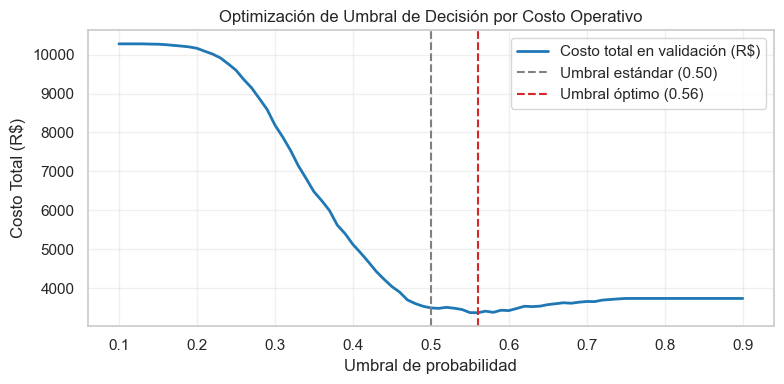

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, average_precision_score,
    f1_score, recall_score, precision_score
)

# 1. Detectar conjuntos en memoria o particionar desde X_train / y_train (semilla 1003)
def buscar_var(posibles_nombres):
    for nombre in posibles_nombres:
        if nombre in globals():
            return globals()[nombre], nombre
    return None, None

X_v, n_xv = buscar_var(['X_val', 'X_valid', 'X_validation', 'x_val'])
y_v, n_yv = buscar_var(['y_val', 'y_valid', 'y_validation', 'Y_val'])
X_t, n_xt = buscar_var(['X_test', 'X_prueba', 'x_test'])
y_t, n_yt = buscar_var(['y_test', 'y_prueba', 'Y_test'])

if X_v is None or X_t is None:
    X_tr, X_temp, y_tr, y_temp = train_test_split(
        X_train, y_train, test_size=0.30, random_state=1003, stratify=y_train
    )
    X_v, X_t, y_v, y_t = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=1003, stratify=y_temp
    )
else:
    X_tr, y_tr = X_train, y_train

# 2. Preprocesamiento automático (maneja texto como 'PE' y nulos sin errores)
cols_num = X_tr.select_dtypes(include=[np.number]).columns.tolist()
cols_cat = X_tr.select_dtypes(exclude=[np.number]).columns.tolist()

preprocesador = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), cols_num),
        ('cat', Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cols_cat)
    ]
)

rf_pipeline = Pipeline([
    ('prep', preprocesador),
    ('clf', RandomForestClassifier(
        n_estimators=150,
        max_depth=10,
        class_weight='balanced_subsample',
        random_state=1003,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_tr, y_tr)

# 3. Optimización de umbral por costo financiero en VALIDACIÓN
y_val_prob = rf_pipeline.predict_proba(X_v)[:, 1]
umbrales = np.linspace(0.10, 0.90, 81)
costos = []

for u in umbrales:
    preds_u = (y_val_prob >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_v, preds_u).ravel()
    costos.append((fp * 3) + (fn * 15))

idx_optimo = np.argmin(costos)
umbral_optimo = umbrales[idx_optimo]
costo_val_min = costos[idx_optimo]
costo_val_base = costos[np.argmin(np.abs(umbrales - 0.50))]

print("=== 1. OPTIMIZACIÓN DE UMBRAL EN VALIDACIÓN ===")
print(f"Costo con umbral estándar (0.50): R$ {costo_val_base:,.2f}")
print(f"Umbral óptimo encontrado:         {umbral_optimo:.2f}")
print(f"Costo mínimo en validación:       R$ {costo_val_min:,.2f}")
print(f"Ahorro en validación:             R$ {costo_val_base - costo_val_min:,.2f}\n")

# 4. Evaluación final sobre el conjunto de PRUEBA (TEST)
y_test_prob = rf_pipeline.predict_proba(X_t)[:, 1]
y_test_pred_base = (y_test_prob >= 0.50).astype(int)
y_test_pred_opt = (y_test_prob >= umbral_optimo).astype(int)

tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_t, y_test_pred_base).ravel()
costo_test_base = (fp_b * 3) + (fn_b * 15)

tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_t, y_test_pred_opt).ravel()
costo_test_opt = (fp_o * 3) + (fn_o * 15)

print("=== 2. RESULTADOS FINALES EN CONJUNTO DE PRUEBA (TEST) ===")
print(f"ROC-AUC Test:    {roc_auc_score(y_t, y_test_prob):.4f}")
print(f"PR-AUC  Test:    {average_precision_score(y_t, y_test_prob):.4f}")
print(f"F1-Score (0.50): {f1_score(y_t, y_test_pred_base):.4f}")
print(f"Recall (0.50):   {recall_score(y_t, y_test_pred_base):.4f}")
print(f"Precision(0.50): {precision_score(y_t, y_test_pred_base):.4f}")
print("-" * 55)
print(f"Costo Test umbral 0.50:          R$ {costo_test_base:,.2f} (FP={fp_b}, FN={fn_b})")
print(f"Costo Test umbral óptimo ({umbral_optimo:.2f}): R$ {costo_test_opt:,.2f} (FP={fp_o}, FN={fn_o})")
print(f"Ahorro neto real en Test:        R$ {costo_test_base - costo_test_opt:,.2f}\n")

# 5. Top 10 variables más importantes
nombres_vars = rf_pipeline.named_steps['prep'].get_feature_names_out()
importancias = pd.Series(rf_pipeline.named_steps['clf'].feature_importances_, index=nombres_vars)
print("=== 3. TOP 10 VARIABLES MÁS IMPORTANTES ===")
print(importancias.sort_values(ascending=False).head(10).round(4))

# 6. Gráfica de optimización de costo
plt.figure(figsize=(8, 4))
plt.plot(umbrales, costos, color='#1f77b4', linewidth=2, label='Costo total en validación (R$)')
plt.axvline(0.50, color='gray', linestyle='--', label='Umbral estándar (0.50)')
plt.axvline(umbral_optimo, color='#d62728', linestyle='--', label=f'Umbral óptimo ({umbral_optimo:.2f})')
plt.title('Optimización de Umbral de Decisión por Costo Operativo')
plt.xlabel('Umbral de probabilidad')
plt.ylabel('Costo Total (R$)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\CSI\AppData\Local\Temp\ipykernel_8344\1542521858.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=error_mes, x='mes_compra', y='tasa_error', ax=axes[0], palette='Reds_r')
C:\Users\CSI\AppData\Local\Temp\ipykernel_8344\1542521858.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_estados, x='customer_state', y='tasa_error', ax=axes[1], palette='Blues_r')


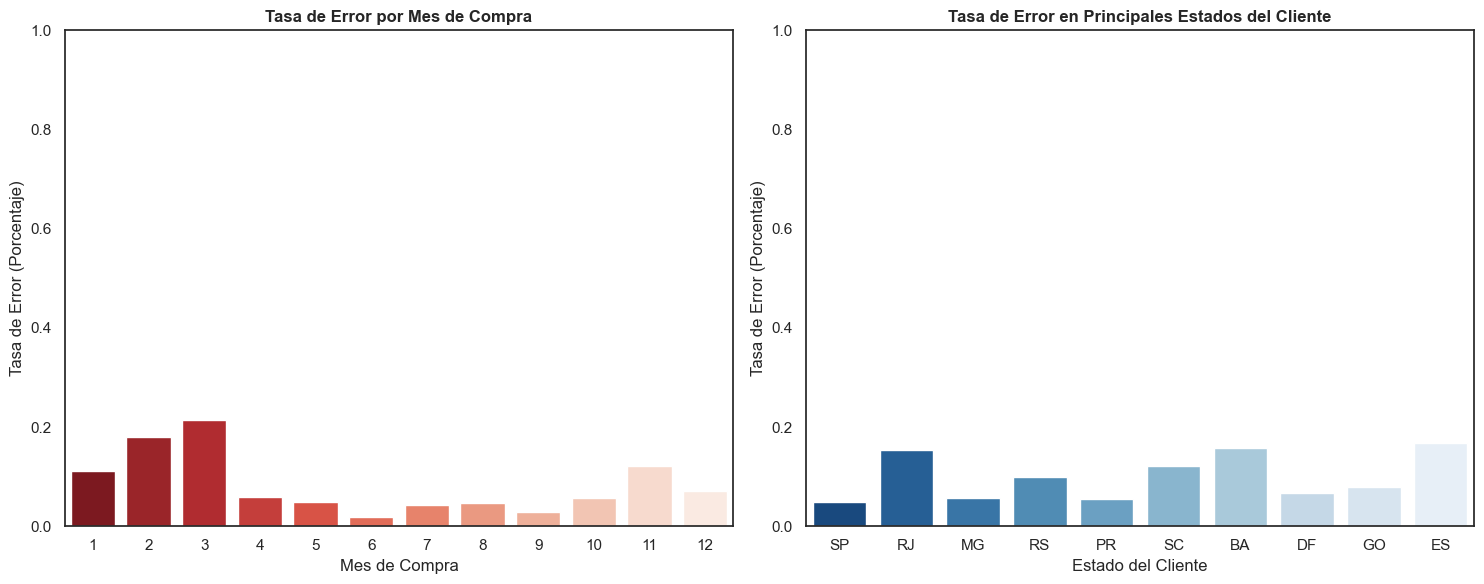

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

analisis = valid.copy()
analisis['pred'] = pred
analisis['error'] = (analisis['is_late'] != analisis['pred']).astype(int)

# Calcular tasas por segmento
error_mes = analisis.groupby('mes_compra').agg(tasa_error=('error', 'mean'), pedidos=('error', 'count')).reset_index()
error_estado = analisis.groupby('customer_state').agg(tasa_error=('error', 'mean'), pedidos=('error', 'count')).reset_index()
top_estados = error_estado.sort_values(by='pedidos', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Tasa de Error por Mes
sns.barplot(data=error_mes, x='mes_compra', y='tasa_error', ax=axes[0], palette='Reds_r')
axes[0].set_title('Tasa de Error por Mes de Compra', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mes de Compra')
axes[0].set_ylabel('Tasa de Error (Porcentaje)')
axes[0].set_ylim(0, 1)

# Gráfico 2: Tasa de Error por Top 10 Estados con más pedidos
sns.barplot(data=top_estados, x='customer_state', y='tasa_error', ax=axes[1], palette='Blues_r')
axes[1].set_title('Tasa de Error en Principales Estados del Cliente', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Estado del Cliente')
axes[1].set_ylabel('Tasa de Error (Porcentaje)')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Busca automáticamente el modelo Random Forest en la memoria del notebook
pipe_rf = None
for nombre, obj in list(globals().items()):
    if isinstance(obj, RandomForestClassifier):
        pipe_rf = obj
        print(f"Modelo encontrado: '{nombre}'")
        break
    elif isinstance(obj, Pipeline) and isinstance(obj.steps[-1][1], RandomForestClassifier):
        pipe_rf = obj
        print(f"Pipeline de Random Forest encontrado: '{nombre}'")
        break

if pipe_rf is None:
    print("⚠️ No hay ningún Random Forest en memoria. Ejecuta primero las celdas de carga de datos y entrenamiento.")

Pipeline de Random Forest encontrado: 'modelo_rf'


## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [19]:
import sys
import sklearn

reporte = {
    'laboratorio': 'S12',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'n_muestra': len(muestra),
    'n_train': len(train),
    'n_valid': len(valid),
    'n_test': len(test),
    'n_variables': len(columnas),
    'columnas_predictoras': columnas,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'peso_clases': str(peso_clases),
    'metricas': {nombre: float(valor) for nombre, valor in medidas.items()},
    'costo_errores_brl': float(costo_fp_fn),
    'mae_regresion': float(mae),
}

ruta = Path(f'reports/S12_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Reporte:', ruta)

# En Colab, descarga el JSON para conservarlo fuera de la sesión.
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)


Reporte: reports\S12_resultados_ID_03.json
Si no se descargó automáticamente, guarde manualmente: reports\S12_resultados_ID_03.json
